# Monsoon (JJAS) Rainfall over Kerala from NASA IMERG

This notebook analyses rainfall over the Kerala (state in India) region (southwest India) during the 2020 southwest monsoon season (June-September), using NASA's GPM IMERG Final Run daily precipitation product (`GPM_3IMERGDF`, version 07).

**Workflow**
1. Download the daily IMERG files for the season (only if they are not already saved locally).
2. Crop the data to the study region and run basic quality checks (number of days, value range, missing data).
3. Save the cropped data as a NetCDF file.
4. Visualise the rainfall in three ways:
   - a map of seasonal total rainfall (where the rain fell),
   - a time series of area-mean daily rainfall (when it fell),
   - monthly totals (how the season built up and faded).

**Notes**
- Downloaded files are stored in `data/raw/imerg`.
- A free NASA Earthdata account is required for the first download.
- Rainfall is in mm/day; seasonal and monthly totals are in mm.

In [9]:
# %pip install earthaccess xarray netCDF4 dask matplotlib

In [10]:
from pathlib import Path
import numpy as np
import earthaccess
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

# Settings
YEAR = 2020
start, end = f"{YEAR}-06-01", f"{YEAR}-09-30"    # June to Septemper
expected = len(pd.date_range(start, end))         # number of days (122)
bbox = (72, 7, 79, 14)                            # west, south, east, north (Kerala)
rainy_day_mm = 2.5                                # IMD threshold for a rainy day

raw_dir = Path("data/raw/imerg")
out_dir = Path("data/processed")
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

## Functions

In [11]:
def local_files(raw_dir, start, end):
    """Return the sorted IMERG files in raw_dir whose date lies in [start, end]."""
    first, last = start.replace("-", ""), end.replace("-", "")
    # File names look like 3B-DAY.MS.MRG.3IMERG.20200601-S000000-E235959.V07B.nc4
    return sorted(
        f for f in raw_dir.glob("*.nc4")
        if first <= f.name.split("IMERG.")[1][:8] <= last
    )


def get_data(raw_dir, start, end, bbox, expected):
    """Return the local file list, downloading from NASA Earthdata only if needed.

    If all `expected` daily files are already in raw_dir, no login or
    download is done.
    """
    files = local_files(raw_dir, start, end)
    if len(files) == expected:
        print(f"Found all {expected} files locally, skipping download.")
        return files

    earthaccess.login(persist=True)  # asks for username/password the first time
    results = earthaccess.search_data(
        short_name="GPM_3IMERGDF", version="07",
        temporal=(start, end), bounding_box=bbox,
    )
    print(f"Files found online: {len(results)} (expected {expected})")
    assert len(results) == expected, "File count is wrong, check dates/product name"

    earthaccess.download(results, str(raw_dir))
    return local_files(raw_dir, start, end)


def crop(files, bbox):
    """Open the daily files and crop precipitation (mm/day) to bbox."""
    west, south, east, north = bbox
    rain = xr.open_mfdataset(files)["precipitation"]

    # Slice direction depends on whether the latitude axis is ascending
    lat_slice = slice(south, north) if rain.lat[0] < rain.lat[-1] else slice(north, south)
    return rain.sel(lon=slice(west, east), lat=lat_slice)

## Load, check and save

In [12]:
files = get_data(raw_dir, start, end, bbox, expected)
rain = crop(files, bbox)

# Quick checks
print("Dimensions:", dict(rain.sizes))
print("Min / max (mm/day):", float(rain.min()), float(rain.max()))
print("Fraction NaN:", float(rain.isnull().mean()))
assert rain.sizes["time"] == expected, "Unexpected number of days"

rain.to_netcdf(out_dir / f"imerg_kerala_{start}_{end}.nc")

Found all 122 files locally, skipping download.
Dimensions: {'time': 122, 'lon': 70, 'lat': 70}
Min / max (mm/day): 0.0 319.8899841308594
Fraction NaN: 0.0


## Seasonal total and rainy days

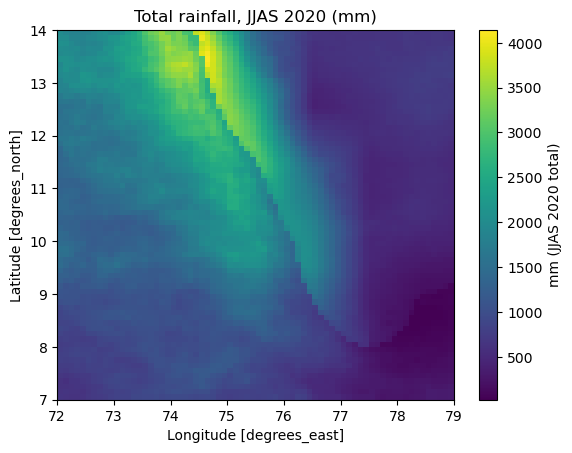

In [13]:
# Seasonal total (min_count=1 keeps cells with no data as NaN instead of 0)
total = rain.sum("time", min_count=1)

total.transpose("lat", "lon").plot(cbar_kwargs={"label": f"mm (JJAS {YEAR} total)"})
plt.title(f"Total rainfall, JJAS {YEAR} (mm)")
# Uncomment below line to save the figure
# plt.savefig(f"imerg_jjas{YEAR}_total.png", dpi=200, bbox_inches="tight")
plt.show()

# Observation:
Seasonal rainfall is strongly controlled by geography. The highest totals (above about 4000 mm) occur along the Western Ghats in the north of the study box, near 74-75°E, 13-14°N, and the maximum may extend beyond the northern edge. Totals fall steadily to the east, with the lowest values (below about 500 mm) in the southeast corner. This pattern is consistent with orographic rainfall on the windward side of the Ghats and a rain shadow on the leeward side.

## Daily rainfall over Kerala

Area-mean daily rainfall: for each day, the average of IMERG rainfall over all grid cells in the study box. This shows the timing of the monsoon, including active spells (high rainfall) and breaks (low rainfall), which the seasonal total map cannot show.

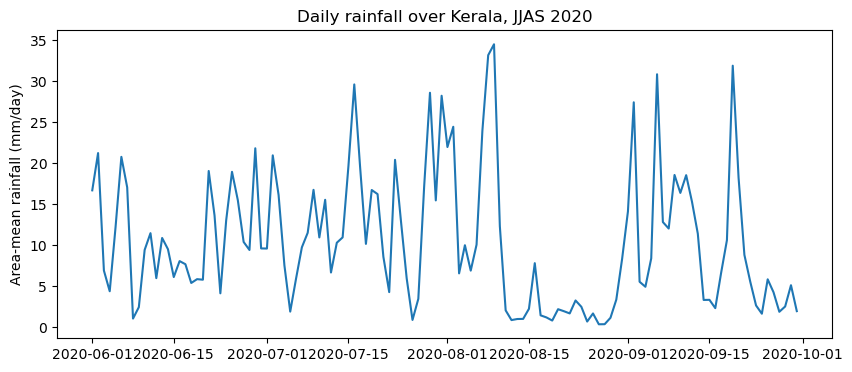

In [14]:
# Average over all grid cells for each day, to show monsoon spells and breaks
daily_mean = rain.mean(["lat", "lon"])

plt.figure(figsize=(10, 4))
plt.plot(pd.date_range(start, end), daily_mean.values)
plt.ylabel("Area-mean rainfall (mm/day)")
plt.title(f"Daily rainfall over Kerala, JJAS {YEAR}")
plt.show()

# Observation:
Rainfall comes in pulses. The strongest spell peaks at roughly 34 mm/day around 8-9 August. This is followed by a sharp drop and a break of about three weeks (roughly 11-31 August) with area-mean rainfall mostly below 3 mm/day. Activity then returns in September, with further peaks of about 27-32 mm/day.

## Monthly rainfall totals

Daily area-mean rainfall summed for each month from June to September. This shows how the monsoon builds up and weakens through the season.

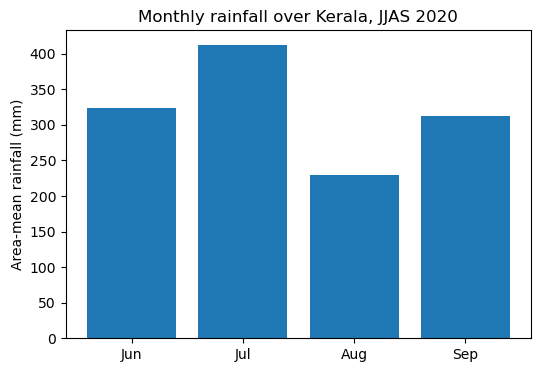

In [15]:
# Sum of the daily area-mean rainfall for each month
monthly = daily_mean.groupby("time.month").sum()

plt.figure(figsize=(6, 4))
plt.bar(["Jun", "Jul", "Aug", "Sep"], monthly.values)
plt.ylabel("Area-mean rainfall (mm)")
plt.title(f"Monthly rainfall over Kerala, JJAS {YEAR}")
plt.show()

# Observation:
July is the wettest month (about 410 mm) and August the driest (about 230 mm). August is notable because it contains both the strongest spell of the season (around 8-9 August) and a long break afterwards, so a few very wet days are outweighed by about three dry weeks. This shows that monthly totals alone can hide how rainfall is distributed within the month, which is why the daily plot is a useful complement.